In [1]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('✅ Dispositivo en uso:', device)

✅ Dispositivo en uso: cpu


In [3]:
latent_dim = 100
img_size = 28*28
batch_size = 128
lr = 0.0002
epochs = 50

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

dataset = datasets.MNIST(root='data', train=True, transform=transform, download=True)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
print('Total de imágenes:', len(dataset))

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [00:08<00:00, 1179207.96it/s]


Extracting data/MNIST/raw/train-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 148461.70it/s]


Extracting data/MNIST/raw/train-labels-idx1-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1648877/1648877 [00:03<00:00, 509975.91it/s]


Extracting data/MNIST/raw/t10k-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4542/4542 [00:00<00:00, 823557.36it/s]

Extracting data/MNIST/raw/t10k-labels-idx1-ubyte.gz to data/MNIST/raw

Total de imágenes: 60000


In [5]:
# Definición del Modelo GAN

# Sección Generador
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, img_size),
            nn.Tanh()
        )
    def forward(self, z):
        img = self.model(z)
        return img.view(-1, 1, 28, 28)

# Sección Discriminador
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(img_size, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )
    def forward(self, img):
        x = img.view(img.size(0), -1)
        return self.model(x)

G = Generator().to(device)
D = Discriminator().to(device)
print('Modelos inicializados ✅')

Modelos inicializados ✅


In [7]:
criterion = nn.BCELoss()
optimizer_G = optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D = optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))

In [9]:
# Función auxiliar para visualización de imágenes
def show_generated_images(epoch):
    z = torch.randn(16, latent_dim, device=device)
    gen_imgs = G(z).detach().cpu()
    gen_imgs = (gen_imgs + 1) / 2
    fig, axes = plt.subplots(4, 4, figsize=(6, 6))
    for i, ax in enumerate(axes.flatten()):
        ax.imshow(gen_imgs[i][0], cmap='gray')
        ax.axis('off')
    plt.suptitle(f'Imágenes generadas - Época {epoch}')
    plt.show()

Época [1/50]  |  Loss D: 0.6237  |  Loss G: 1.6962


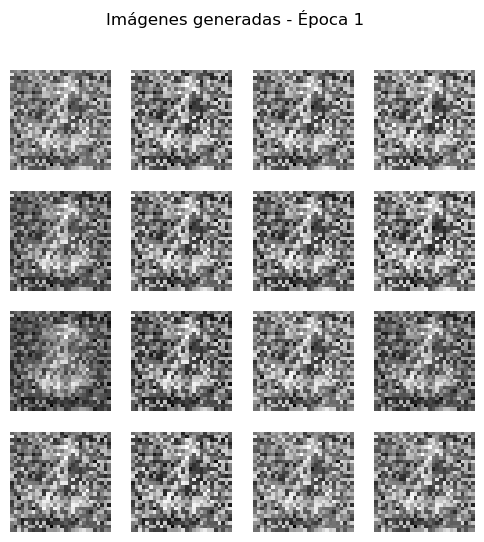

Época [2/50]  |  Loss D: 0.9054  |  Loss G: 1.6851
Época [3/50]  |  Loss D: 0.8590  |  Loss G: 1.2960
Época [4/50]  |  Loss D: 0.9079  |  Loss G: 1.3541
Época [5/50]  |  Loss D: 0.7192  |  Loss G: 1.6430
Época [6/50]  |  Loss D: 0.9775  |  Loss G: 3.3303
Época [7/50]  |  Loss D: 1.2239  |  Loss G: 4.1679
Época [8/50]  |  Loss D: 0.6750  |  Loss G: 1.5309
Época [9/50]  |  Loss D: 0.7434  |  Loss G: 1.4566
Época [10/50]  |  Loss D: 0.9196  |  Loss G: 1.0210


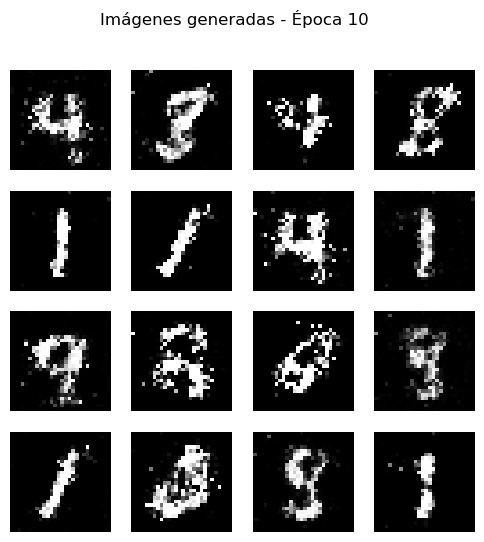

Época [11/50]  |  Loss D: 0.9376  |  Loss G: 1.4992
Época [12/50]  |  Loss D: 0.9295  |  Loss G: 1.4754
Época [13/50]  |  Loss D: 1.0748  |  Loss G: 1.4931
Época [14/50]  |  Loss D: 1.0865  |  Loss G: 0.7592
Época [15/50]  |  Loss D: 1.1067  |  Loss G: 0.9773
Época [16/50]  |  Loss D: 1.1921  |  Loss G: 1.8053
Época [17/50]  |  Loss D: 1.0555  |  Loss G: 0.8828
Época [18/50]  |  Loss D: 1.1129  |  Loss G: 0.9236
Época [19/50]  |  Loss D: 1.0702  |  Loss G: 1.1156
Época [20/50]  |  Loss D: 1.1075  |  Loss G: 1.2384


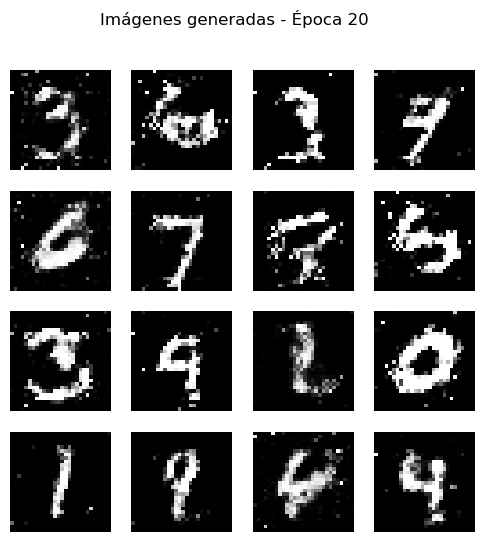

Época [21/50]  |  Loss D: 1.1457  |  Loss G: 0.7922
Época [22/50]  |  Loss D: 1.0765  |  Loss G: 1.0946
Época [23/50]  |  Loss D: 1.1408  |  Loss G: 0.9105
Época [24/50]  |  Loss D: 1.2894  |  Loss G: 0.5742
Época [25/50]  |  Loss D: 1.1510  |  Loss G: 1.4638
Época [26/50]  |  Loss D: 1.1935  |  Loss G: 0.7377
Época [27/50]  |  Loss D: 1.1583  |  Loss G: 1.2184
Época [28/50]  |  Loss D: 1.1925  |  Loss G: 0.7736
Época [29/50]  |  Loss D: 1.0556  |  Loss G: 1.0031
Época [30/50]  |  Loss D: 1.2331  |  Loss G: 0.7639


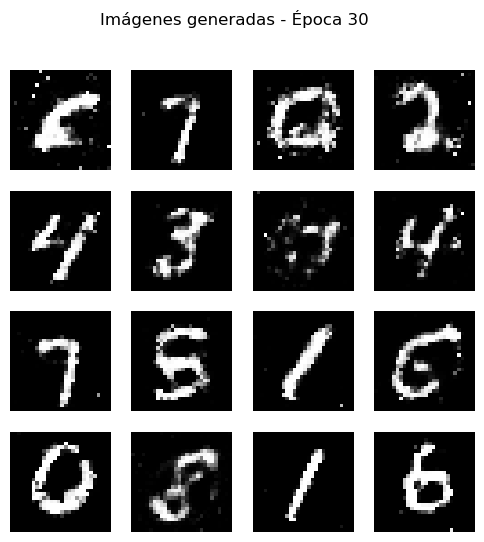

Época [31/50]  |  Loss D: 1.2449  |  Loss G: 1.1744
Época [32/50]  |  Loss D: 1.1348  |  Loss G: 1.0545
Época [33/50]  |  Loss D: 1.2489  |  Loss G: 1.1616
Época [34/50]  |  Loss D: 1.2927  |  Loss G: 1.8622
Época [35/50]  |  Loss D: 1.1626  |  Loss G: 0.8766
Época [36/50]  |  Loss D: 1.1377  |  Loss G: 1.4909
Época [37/50]  |  Loss D: 1.0883  |  Loss G: 1.0774
Época [38/50]  |  Loss D: 1.1336  |  Loss G: 1.0642
Época [39/50]  |  Loss D: 1.0851  |  Loss G: 0.9618
Época [40/50]  |  Loss D: 1.2864  |  Loss G: 1.7131


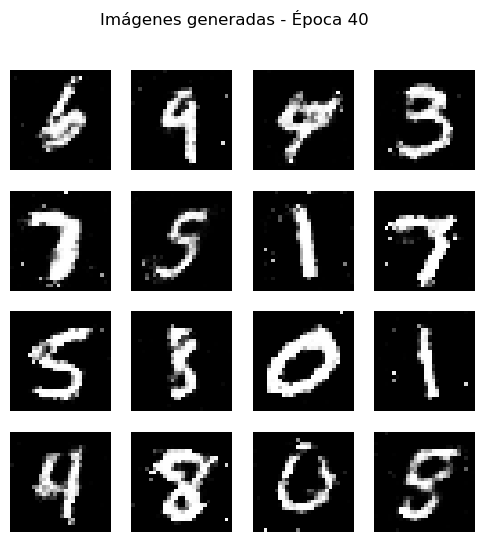

Época [41/50]  |  Loss D: 1.2537  |  Loss G: 1.5414
Época [42/50]  |  Loss D: 1.0685  |  Loss G: 1.2404
Época [43/50]  |  Loss D: 1.2344  |  Loss G: 1.4599
Época [44/50]  |  Loss D: 1.1434  |  Loss G: 1.0900
Época [45/50]  |  Loss D: 1.1015  |  Loss G: 0.9596
Época [46/50]  |  Loss D: 1.0851  |  Loss G: 1.5150
Época [47/50]  |  Loss D: 1.1183  |  Loss G: 1.4848
Época [48/50]  |  Loss D: 1.0514  |  Loss G: 0.8790
Época [49/50]  |  Loss D: 1.0763  |  Loss G: 0.8869
Época [50/50]  |  Loss D: 1.0846  |  Loss G: 0.7081


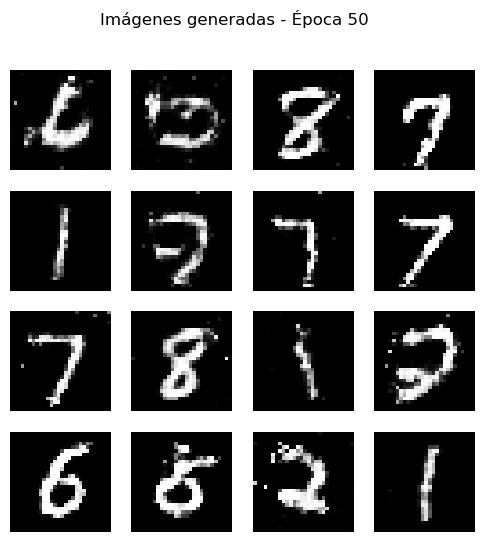

In [11]:
for epoch in range(1, epochs+1):
    for imgs, _ in dataloader:
        real_imgs = imgs.to(device)
        real_labels = torch.ones(imgs.size(0), 1, device=device)
        fake_labels = torch.zeros(imgs.size(0), 1, device=device)
        outputs_real = D(real_imgs)
        loss_real = criterion(outputs_real, real_labels)
        z = torch.randn(imgs.size(0), latent_dim, device=device)
        fake_imgs = G(z)
        outputs_fake = D(fake_imgs.detach())
        loss_fake = criterion(outputs_fake, fake_labels)
        loss_D = loss_real + loss_fake
        optimizer_D.zero_grad()
        loss_D.backward()
        optimizer_D.step()
        z = torch.randn(imgs.size(0), latent_dim, device=device)
        fake_imgs = G(z)
        outputs = D(fake_imgs)
        loss_G = criterion(outputs, real_labels)
        optimizer_G.zero_grad()
        loss_G.backward()
        optimizer_G.step()
    print(f'Época [{epoch}/{epochs}]  |  Loss D: {loss_D.item():.4f}  |  Loss G: {loss_G.item():.4f}')
    if epoch % 10 == 0 or epoch == 1:
        show_generated_images(epoch)

In [13]:
import numpy as np


In [19]:
batch_size = 128
epochs_ae = 50   # sube a 20-30 para mejor calidad
epochs_vae = 40  # sube a 20-30 para mejor calidad
lr = 1e-3

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # [-1, 1]
])

train_ds = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root='data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

len(train_ds), len(test_ds)

(60000, 10000)

In [21]:
# Modelo Autoencoder (AE)
img_dim = 28*28
latent_dim = 32

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(img_dim, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, img_dim), nn.Tanh()  # salida [-1,1]
        )
    def forward(self, x):
        x = x.view(x.size(0), -1)
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat

ae = Autoencoder().to(device)
opt_ae = optim.Adam(ae.parameters(), lr=lr)
loss_fn = nn.MSELoss()

In [23]:
### Entrenamiento AE
ae.train()
for epoch in range(1, epochs_ae+1):
    running = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        opt_ae.zero_grad()
        x_hat = ae(x)
        loss = loss_fn(x_hat, x.view(x.size(0), -1))
        loss.backward()
        opt_ae.step()
        running += loss.item()*x.size(0)
    print(f"AE Epoch {epoch:02d}/{epochs_ae} - loss: {running/len(train_ds):.4f}")

torch.save(ae.state_dict(), 'ae_mnist.pth')
print('✅ AE guardado: ae_mnist.pth')

AE Epoch 01/50 - loss: 0.1530
AE Epoch 02/50 - loss: 0.0704
AE Epoch 03/50 - loss: 0.0554
AE Epoch 04/50 - loss: 0.0478
AE Epoch 05/50 - loss: 0.0429
AE Epoch 06/50 - loss: 0.0395
AE Epoch 07/50 - loss: 0.0368
AE Epoch 08/50 - loss: 0.0345
AE Epoch 09/50 - loss: 0.0328
AE Epoch 10/50 - loss: 0.0313
AE Epoch 11/50 - loss: 0.0301
AE Epoch 12/50 - loss: 0.0291
AE Epoch 13/50 - loss: 0.0282
AE Epoch 14/50 - loss: 0.0274
AE Epoch 15/50 - loss: 0.0267
AE Epoch 16/50 - loss: 0.0262
AE Epoch 17/50 - loss: 0.0257
AE Epoch 18/50 - loss: 0.0253
AE Epoch 19/50 - loss: 0.0248
AE Epoch 20/50 - loss: 0.0244
AE Epoch 21/50 - loss: 0.0241
AE Epoch 22/50 - loss: 0.0238
AE Epoch 23/50 - loss: 0.0233
AE Epoch 24/50 - loss: 0.0231
AE Epoch 25/50 - loss: 0.0227
AE Epoch 26/50 - loss: 0.0225
AE Epoch 27/50 - loss: 0.0223
AE Epoch 28/50 - loss: 0.0221
AE Epoch 29/50 - loss: 0.0219
AE Epoch 30/50 - loss: 0.0218
AE Epoch 31/50 - loss: 0.0215
AE Epoch 32/50 - loss: 0.0214
AE Epoch 33/50 - loss: 0.0212
AE Epoch 3

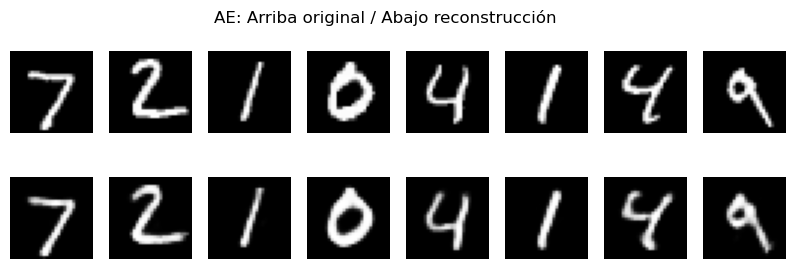

In [25]:
### Visualización AE: original vs reconstrucción
ae.eval()
with torch.no_grad():
    imgs, _ = next(iter(test_loader))
    imgs = imgs.to(device)
    recon = ae(imgs).view(-1, 1, 28, 28)
    # re-escalar de [-1,1] a [0,1]
    show_n = 8
    plt.figure(figsize=(10,3))
    for i in range(show_n):
        plt.subplot(2, show_n, i+1)
        plt.imshow((imgs[i].cpu().squeeze(0)+1)/2, cmap='gray')
        plt.axis('off')
        plt.subplot(2, show_n, show_n+i+1)
        plt.imshow((recon[i].cpu().squeeze(0)+1)/2, cmap='gray')
        plt.axis('off')
    plt.suptitle('AE: Arriba original / Abajo reconstrucción')
    plt.show()

In [29]:
def add_salt_and_pepper(x, amount=0.2):
    # x en [-1,1], tensor (B,1,28,28)
    x = x.clone()
    mask = torch.rand_like(x)
    x[mask < amount/2] = 1.0  # sal
    x[(mask >= amount/2) & (mask < amount)] = -1.0  # pimienta
    return x

ae.eval()
xs, ys = next(iter(test_loader))
xs = xs.to(device)

# 50% normales, 50% anómalas
half = xs.size(0)//2
x_normal = xs[:half]
x_anom = add_salt_and_pepper(xs[half:], amount=0.3)
x_mix = torch.cat([x_normal, x_anom], dim=0)
y_true = torch.cat([torch.zeros(half), torch.ones(xs.size(0)-half)])  # 0 normal, 1 anómalo

with torch.no_grad():
    rec = ae(x_mix).view(x_mix.size(0), 1, 28, 28)
    # error MSE por muestra
    err = torch.mean((rec - x_mix)**2, dim=(1,2,3)).cpu()

thr = err.mean() + 2*err.std()  # umbral simple
y_pred = (err > thr).float()
precision = ( (y_pred==1) & (y_true==1) ).sum() / max(1,(y_pred==1).sum())
recall    = ( (y_pred==1) & (y_true==1) ).sum() / max(1,(y_true==1).sum())
acc       = (y_pred==y_true).sum() / y_true.numel()
print(f"Umbral: {thr:.4f} | Precisión: {precision:.3f} | Recall: {recall:.3f} | Acc: {acc:.3f}")

# Visualizar algunas anómalas detectadas
idxs = torch.where(y_pred==1)[0][:8]
plt.figure(figsize=(10,3))
for i, idx in enumerate(idxs):
    plt.subplot(2,8,i+1)
    plt.imshow(((x_mix[idx].cpu().squeeze(0)+1)/2), cmap='gray')
    plt.axis('off')
    plt.subplot(2,8,8+i+1)
    plt.imshow(((rec[idx].cpu().squeeze(0)+1)/2), cmap='gray')
    plt.axis('off')
plt.suptitle('Detección de anomalías: Arriba entrada / Abajo reconstrucción (AE)')
plt.show();

Umbral: 0.9047 | Precisión: 0.000 | Recall: 0.000 | Acc: 0.500


<Figure size 1000x300 with 0 Axes>